# Lab: Using Pretrained CNNs — AlexNet, VGG16, ResNet18
**Course:** Computational Approaches in Crop Sciences  
**Duration:** 90–120 minutes  
**Environment:** Google Colab (CPU works; GPU optional)  
**Deliverable:** Completed notebook with figures, table, and written interpretations.

## Scientific question
How do network architectures differ in classification behavior, robustness to perturbations, efficiency, and the image representations they learn?

### Objectives
1. Load pretrained networks without training.
2. Apply *model-specific* preprocessing and obtain ImageNet class predictions.
3. Compare top-5 outputs, model sizes, and inference times on identical images.
4. Test sensitivity to image transformations.
5. Extract learned embeddings and analyze similarities.
6. Distinguish classification, feature extraction, and fine-tuning.

**Important:** Softmax scores are not calibrated probabilities of correctness. ImageNet labels are not a crop-disease vocabulary. Timing and predictions will depend on hardware and input images.

**New visual investigations:** architecture flow, weight allocation, top-5 prediction plots, inference/memory tradeoffs, perturbation heatmaps, and convolutional activation maps.

## Part 0 — Setup
Run this cell. On Colab, PyTorch and TorchVision are usually installed. Model weights will download on first use (~0.8 GB total for these three models). If there is a compatibility error between torch and torchvision, restart with a compatible Colab runtime rather than upgrading one alone.

In [1]:
import io, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps
import torch
import torchvision
from torchvision.models import (alexnet, vgg16, resnet18,
    AlexNet_Weights, VGG16_Weights, ResNet18_Weights)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('device:', DEVICE)

def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()


torch: 2.11.0+cpu | torchvision: 0.26.0+cpu
device: cpu


## Part 1 — Load and examine the models
All pretrained weights below correspond to ImageNet-1K. We deliberately choose *specific* weight versions rather than `DEFAULT` so the lab is reproducible across TorchVision updates.

**Before running:** predict which network has the most parameters, which will be fastest, and which will perform best on photographs.

In [2]:
SPECS = {
    'AlexNet': (alexnet, AlexNet_Weights.IMAGENET1K_V1),
    'VGG16': (vgg16, VGG16_Weights.IMAGENET1K_V1),
    'ResNet18': (resnet18, ResNet18_Weights.IMAGENET1K_V1),
}
models, weights_map = {}, {}
for name, (constructor, weights) in SPECS.items():
    model = constructor(weights=weights).to(DEVICE).eval()
    models[name] = model
    weights_map[name] = weights
    print(name, 'loaded')

stats = pd.DataFrame([
    {'model': name,
     'parameters_M': sum(p.numel() for p in model.parameters()) / 1e6,
     'trainable_parameters_M': sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6}
    for name, model in models.items()
])
display(stats)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 149MB/s]


AlexNet loaded
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 78.5MB/s]


VGG16 loaded
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


ResNet18 loaded


,model,parameters_M,trainable_parameters_M
0,AlexNet,61.100840,61.100840
1,VGG16,138.357544,138.357544
2,ResNet18,11.689512,11.689512


**Question 1.** Which model has the most parameters? Does the number of parameters measure computational operations? Explain why the distinction matters.

**Question 2.** Inspect the models below. How is ResNet18's architecture different from a simple stack of convolutions?

In [3]:
# Inspect the first few blocks; uncomment one full model if you wish.
for name, model in models.items():
    print(f'\n{name}:', list(model.named_children())[:2])
# print(models['ResNet18'])


AlexNet: [('features', Sequential(
  (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU(inplace=True)
  (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU(inplace=True)
  (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
)), ('avgpool', AdaptiveAvgPool2d(output_size=(6, 6)))]

VGG16: [('features', Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, ke

## Visual A — What changes from AlexNet to VGG16 to ResNet18?

The diagrams below are **conceptual** rather than layer-by-layer schematics. They show the different organizational ideas, especially ResNet's skip connections. The plot of actual network stages underneath provides a second, quantitative view.

**Observe:** AlexNet uses relatively large early kernels and substantial dense layers; VGG16 repeatedly stacks small convolutions; ResNet18 has shortcut additions. Residual connections do **not** imply that ResNet18 contains fewer convolutional layers than AlexNet.

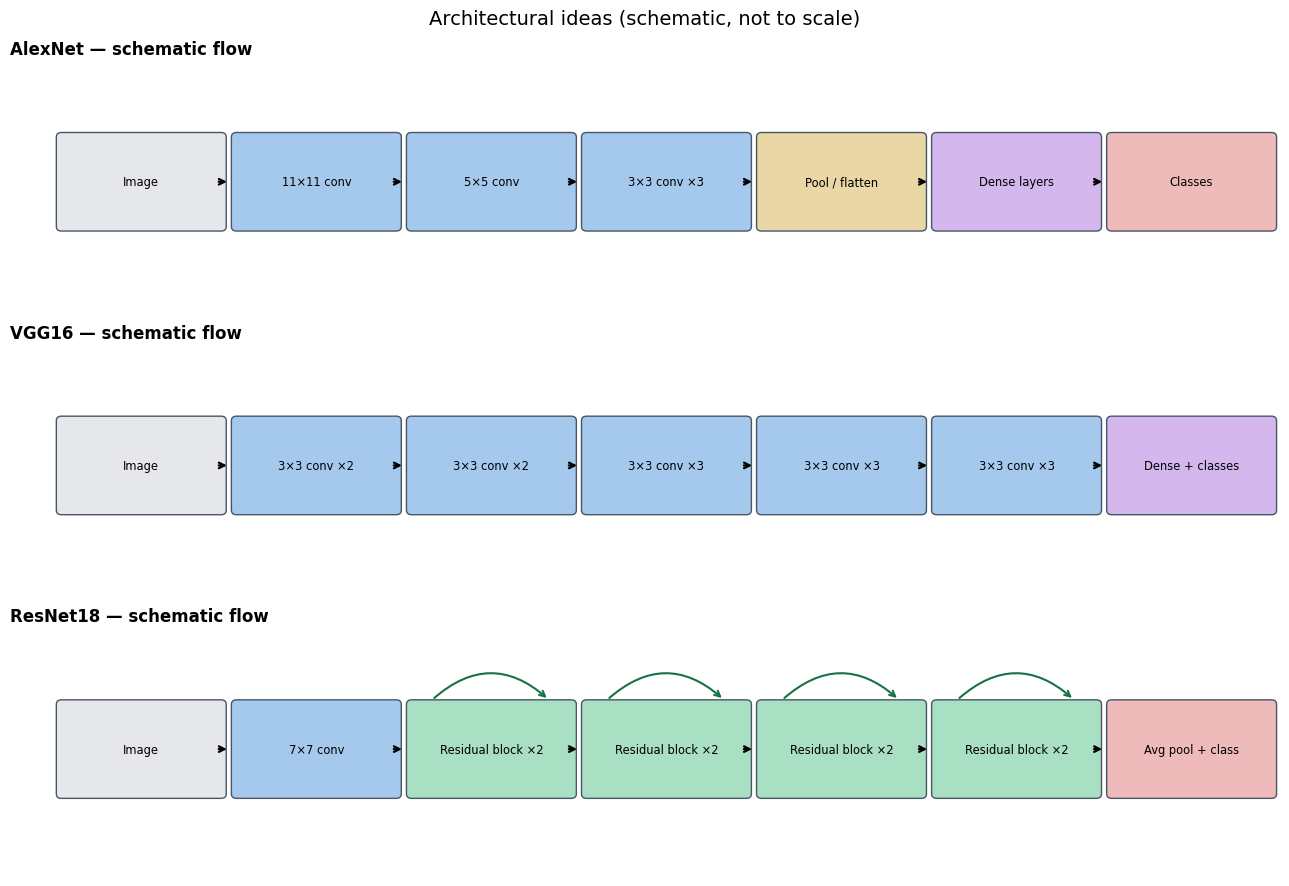

Actual parameter distribution (millions):


component,Classifier,Convolutional features,Dense classifier,Residual stages,Stem
model,,,,,
AlexNet,0.00,2.47,58.63,0.00,0.00
ResNet18,0.51,0.00,0.00,11.17,0.01
VGG16,0.00,14.71,123.64,0.00,0.00


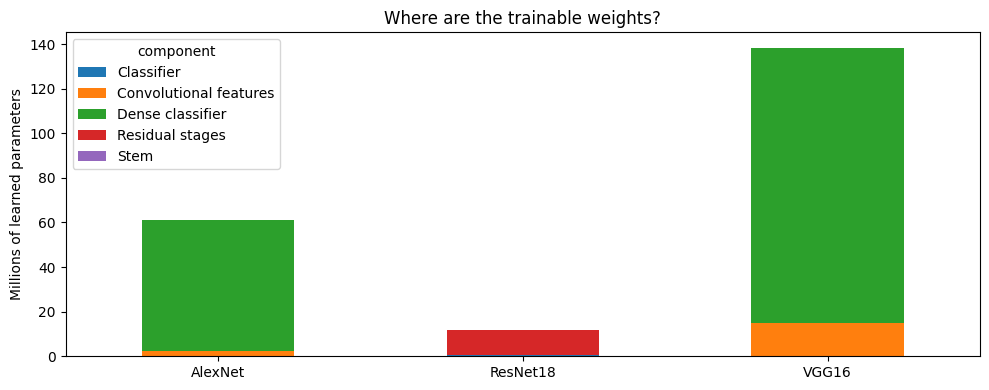

In [4]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, axes = plt.subplots(3, 1, figsize=(13, 9))
blueprints = {
    'AlexNet': [('Image','input'),('11×11 conv','conv'),('5×5 conv','conv'),('3×3 conv ×3','conv'),('Pool / flatten','pool'),('Dense layers','dense'),('Classes','output')],
    'VGG16': [('Image','input'),('3×3 conv ×2','conv'),('3×3 conv ×2','conv'),('3×3 conv ×3','conv'),('3×3 conv ×3','conv'),('3×3 conv ×3','conv'),('Dense + classes','dense')],
    'ResNet18': [('Image','input'),('7×7 conv','conv'),('Residual block ×2','res'),('Residual block ×2','res'),('Residual block ×2','res'),('Residual block ×2','res'),('Avg pool + class','output')]
}
colors = {'input':'#e6e7eb','conv':'#a5c9ec','pool':'#ead7a6','dense':'#d3b7ed','res':'#a9dfc2','output':'#efbaba'}
for ax,(name,blocks) in zip(axes,blueprints.items()):
    ax.set_xlim(-0.3, 7.1); ax.set_ylim(-0.55,1.1); ax.axis('off')
    for j,(label,kind) in enumerate(blocks):
        x=j*1.02
        patch=FancyBboxPatch((x,0),0.93,.6,boxstyle='round,pad=0.03',facecolor=colors[kind],edgecolor='#485566')
        ax.add_patch(patch)
        ax.text(x+.465,.3,label,ha='center',va='center',fontsize=8.3)
        if j:ax.annotate('',xy=(x-.04,.3),xytext=(x-.12,.3),arrowprops={'arrowstyle':'->','lw':1.6})
        if kind=='res':
            ax.annotate('',xy=(x+.80,.63),xytext=(x+.12,.63),arrowprops={'arrowstyle':'->','lw':1.5,'color':'#177245','connectionstyle':'arc3,rad=-.45'})
    ax.set_title(f'{name} — schematic flow',loc='left',fontsize=12,fontweight='bold')
plt.suptitle('Architectural ideas (schematic, not to scale)',fontsize=14)
plt.tight_layout();plt.show()

# Quantitative stages: number of weights grouped by top-level layer families
rows=[]
for model_name, net in models.items():
    if model_name in ('AlexNet','VGG16'):
        parts={'Convolutional features':net.features,'Dense classifier':net.classifier}
    else:
        parts={'Stem':torch.nn.Sequential(net.conv1,net.bn1),
               'Residual stages':torch.nn.Sequential(net.layer1,net.layer2,net.layer3,net.layer4),
               'Classifier':net.fc}
    for part,module in parts.items():
        rows.append({'model':model_name,'component':part,'parameters_M':sum(q.numel() for q in module.parameters())/1e6})
component_df=pd.DataFrame(rows)
print('Actual parameter distribution (millions):')
display(component_df.pivot(index='model',columns='component',values='parameters_M').fillna(0).round(2))
ax=component_df.pivot(index='model',columns='component',values='parameters_M').fillna(0).plot(kind='bar',stacked=True,figsize=(10,4))
ax.set_ylabel('Millions of learned parameters');ax.set_xlabel('');ax.set_title('Where are the trainable weights?');plt.xticks(rotation=0);plt.tight_layout();plt.show()

**Questions A1–A3.** Why can VGG16 have more parameters than ResNet18 despite its different depth? What does the green shortcut represent? Which models devote most of their parameters to a dense classifier?

## Part 2 — Images and predictions
The sample photograph comes from the PyTorch Hub demonstration. Add 2–5 of your own RGB photographs using the upload cell below. For an agricultural extension, use images of crops, leaves, equipment or field scenes.

For each model, use the preprocessing associated with **its own weights**, including resizing/cropping/normalization.

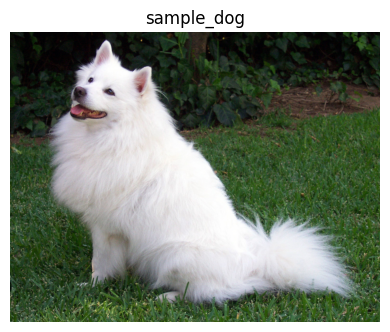

In [5]:
SAMPLE_URL = 'https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg'
try:
    image_bytes = urllib.request.urlopen(SAMPLE_URL, timeout=20).read()
    images = {'sample_dog': Image.open(io.BytesIO(image_bytes)).convert('RGB')}
except Exception as exc:
    print('Sample download failed:', exc)
    images = {}

# Optional: upload your own photographs in Google Colab.
# from google.colab import files
# uploaded = files.upload()
# for filename, contents in uploaded.items():
#     try:
#         images[Path(filename).stem] = Image.open(io.BytesIO(contents)).convert('RGB')
#     except Exception as exc:
#         print('Skipping', filename, exc)

assert images, 'Provide at least one image before continuing.'
fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 4), squeeze=False)
for ax, (name, im) in zip(axes.flat, images.items()):
    ax.imshow(im); ax.set_title(name); ax.axis('off')
plt.tight_layout()


In [6]:
@torch.inference_mode()
def predict(model_name, pil_image, topk=5):
    model = models[model_name]
    w = weights_map[model_name]
    batch = w.transforms()(pil_image.convert('RGB')).unsqueeze(0).to(DEVICE)
    logits = model(batch)[0]
    scores = torch.softmax(logits, dim=0)
    values, indices = scores.topk(topk)
    return [(w.meta['categories'][int(idx)], float(value))
            for idx, value in zip(indices, values)]

rows = []
for image_name, im in images.items():
    for model_name in models:
        for rank, (label, score) in enumerate(predict(model_name, im), start=1):
            rows.append({'image': image_name, 'model': model_name,
                         'rank': rank, 'ImageNet_label': label,
                         'softmax_score': score})
predictions = pd.DataFrame(rows)
display(predictions)


,image,model,rank,ImageNet_label,softmax_score
0,sample_dog,AlexNet,1,Samoyed,0.724477
1,sample_dog,AlexNet,2,wallaby,0.139378
2,sample_dog,AlexNet,3,Pomeranian,0.058750
3,sample_dog,AlexNet,4,Angora,0.022830
4,sample_dog,AlexNet,5,Arctic fox,0.012450
5,sample_dog,VGG16,1,Samoyed,0.839519
6,sample_dog,VGG16,2,Pomeranian,0.032985
7,sample_dog,VGG16,3,Eskimo dog,0.016833
8,sample_dog,VGG16,4,white wolf,0.015952
9,sample_dog,VGG16,5,Great Pyrenees,0.012187


## Visual B — Compare probability distributions, not just winners

A top-1 label hides the information contained in the other predicted classes. The three models have the same ImageNet-1K label vocabulary, but their softmax scores are **not calibrated measures of correctness**. These plots use the first image in the notebook.

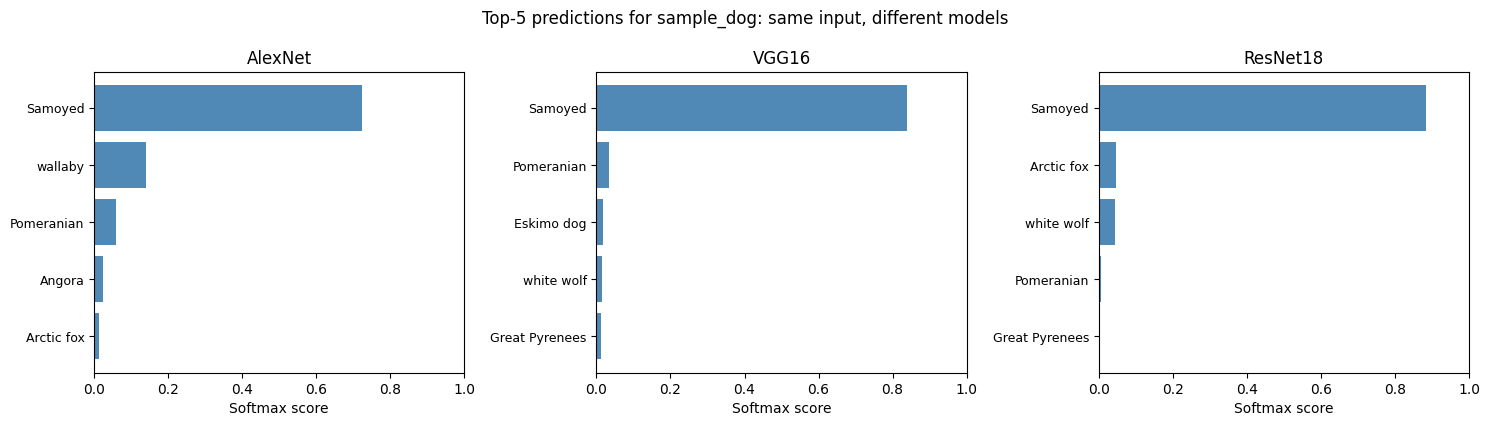

In [7]:
first_image_name, first_image = next(iter(images.items()))
fig, axs = plt.subplots(1,3,figsize=(15,4.3))
for ax,name in zip(axs,models):
    ranked=predict(name, first_image, topk=5)
    labels=[q[0] for q in ranked][::-1]
    scores=[q[1] for q in ranked][::-1]
    ax.barh(range(5),scores,color='#5089b6')
    ax.set_yticks(range(5),labels=labels,fontsize=9)
    ax.set_xlim(0,1);ax.set_xlabel('Softmax score')
    ax.set_title(name)
fig.suptitle(f'Top-5 predictions for {first_image_name}: same input, different models')
plt.tight_layout();plt.show()

**Questions B1–B2.** Do the top-5 class lists overlap? Would a larger softmax score automatically imply a more trustworthy prediction? Explain why not.

**Question 3.** Do the models agree on the top prediction? Are differing softmax scores evidence that one model is more correct? How would you establish correctness?

**Question 4.** What happens when a crop or leaf does not correspond to one of the 1,000 ImageNet classes?

## Part 3 — Computational comparison
We time repeated single-image forward passes. GPU timing needs synchronization and results are hardware-specific. These timings are **illustrative**, not standardized benchmarks.

,model,median_ms,parameters_M
0,AlexNet,84.581774,61.100840
1,VGG16,553.647860,138.357544
2,ResNet18,79.400447,11.689512


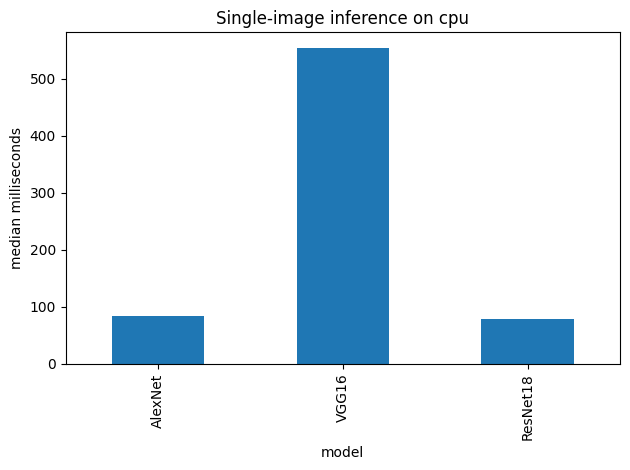

In [8]:
# Use one image for a controlled comparison.
example_name, example_image = next(iter(images.items()))
results = []
for name, model in models.items():
    x = weights_map[name].transforms()(example_image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        for _ in range(3): model(x) # warm-up
        sync()
        timings = []
        for _ in range(10):
            sync(); t0 = time.perf_counter()
            _ = model(x)
            sync(); timings.append((time.perf_counter()-t0)*1000)
    results.append({'model': name, 'median_ms': np.median(timings),
                    'parameters_M': stats.set_index('model').loc[name, 'parameters_M']})
benchmark = pd.DataFrame(results)
display(benchmark)
benchmark.plot(x='model', y='median_ms', kind='bar', legend=False,
               title=f'Single-image inference on {DEVICE}')
plt.ylabel('median milliseconds'); plt.tight_layout(); plt.show()


## Visual C — Efficiency has more than one axis

Parameter count approximates model weight storage; the latency measured here depends on the Colab hardware, processing pipeline, and current load. The bubble diagram shows speed and memory together. It should not be interpreted as a controlled cross-hardware benchmark.

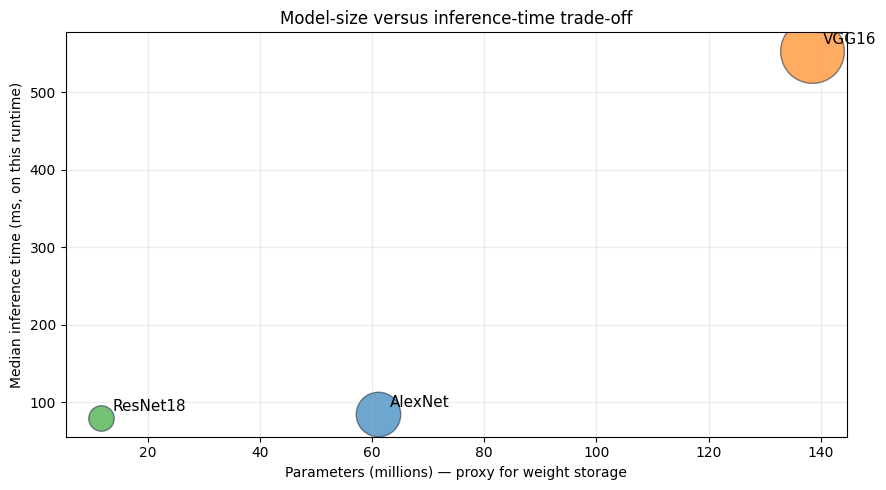

Weight-only storage (float32, no runtime overhead):


,model,parameters_M,approx_weight_MiB
0,AlexNet,61.1,233.1
1,VGG16,138.4,527.8
2,ResNet18,11.7,44.6


In [9]:
fig,ax=plt.subplots(figsize=(9,5))
for _,r in benchmark.iterrows():
    s=float(r['parameters_M'])
    ax.scatter(float(r['parameters_M']),float(r['median_ms']),s=s*14+170,alpha=.65,edgecolors='#374151')
    ax.annotate(r['model'],(r['parameters_M'],r['median_ms']),xytext=(8,5),textcoords='offset points',fontsize=11)
ax.set_xlabel('Parameters (millions) — proxy for weight storage')
ax.set_ylabel('Median inference time (ms, on this runtime)')
ax.set_title('Model-size versus inference-time trade-off')
ax.grid(alpha=.25);plt.tight_layout();plt.show()
print('Weight-only storage (float32, no runtime overhead):')
display(stats[['model','parameters_M']].assign(approx_weight_MiB=lambda d:d.parameters_M*1e6*4/(1024**2)).round(1))

**Questions C1–C2.** Which network is best suited to a resource-constrained device *on your runtime*? Why might model-size ranking differ from latency ranking? What additional measurements would you need for edge deployment (e.g., peak activation memory, power)?

**Question 5.** Is the fastest network necessarily the network with the fewest parameters? How might memory access, architecture and GPU parallelism affect the result?

## Part 4 — Robustness to image changes
Here we change the **input** but leave the pretrained weights unchanged. Interpret this as perturbation sensitivity, not a formal robustness benchmark.

**Hypothesis:** Write a prediction about the consequences of low brightness, rotation and strong cropping before viewing outputs.

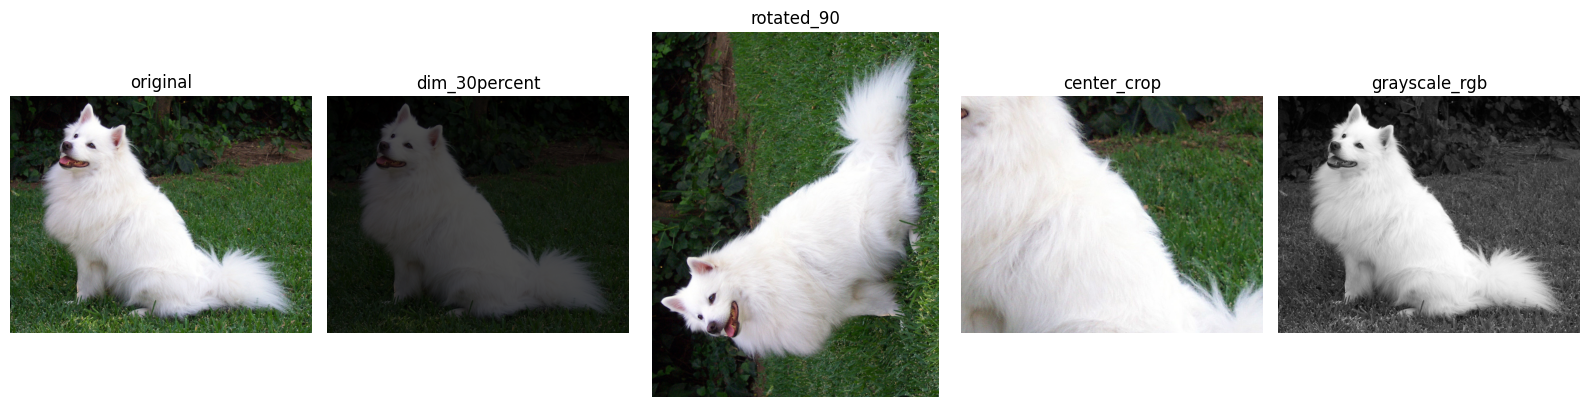

,variant,model,top_label,top_score
0,original,AlexNet,Samoyed,0.724477
1,original,VGG16,Samoyed,0.839519
2,original,ResNet18,Samoyed,0.884623
3,dim_30percent,AlexNet,Samoyed,0.353545
4,dim_30percent,VGG16,Samoyed,0.939957
5,dim_30percent,ResNet18,Samoyed,0.896985
6,rotated_90,AlexNet,Samoyed,0.761050
7,rotated_90,VGG16,Samoyed,0.664552
8,rotated_90,ResNet18,Samoyed,0.462454
9,center_crop,AlexNet,Samoyed,0.350550


In [10]:
def make_variants(im):
    im = im.convert('RGB')
    w, h = im.size
    inset_w, inset_h = max(1, int(w*0.25)), max(1, int(h*0.25))
    return {
        'original': im,
        'dim_30percent': ImageEnhance.Brightness(im).enhance(0.3),
        'rotated_90': im.rotate(90, expand=True),
        'center_crop': im.crop((inset_w, inset_h, w-inset_w, h-inset_h)),
        'grayscale_rgb': ImageOps.grayscale(im).convert('RGB'),
    }
variants = make_variants(example_image)
fig, axs = plt.subplots(1, len(variants), figsize=(16, 4))
for ax, (name, im) in zip(axs, variants.items()):
    ax.imshow(im); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()
variant_rows = []
for variant, im in variants.items():
    for model in models:
        label, score = predict(model, im, topk=1)[0]
        variant_rows.append({'variant': variant, 'model': model,
                             'top_label': label, 'top_score': score})
variant_df = pd.DataFrame(variant_rows)
display(variant_df)


## Visual D — How stable are predictions under changes to the input?

The heatmap below displays the **softmax score of each model's original top-1 class** when the image changes. Holding the label constant makes the values comparable *within each model* across transformations, unlike a chart showing whichever class happens to win on each transformed image.

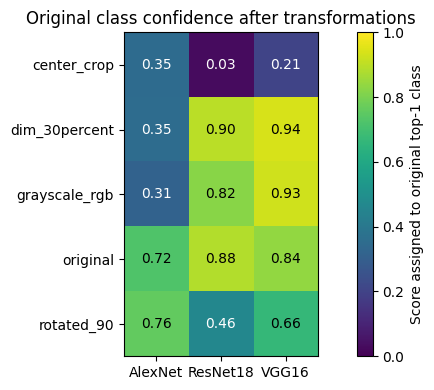

Original top-1 label for each model: {'AlexNet': 'Samoyed', 'VGG16': 'Samoyed', 'ResNet18': 'Samoyed'}


In [11]:
original_labels={name:predict(name,example_image,topk=1)[0][0] for name in models}
robust_rows=[]
for variant,im in variants.items():
    for name in models:
        pred=dict(predict(name,im,topk=1000))
        robust_rows.append({'variant':variant,'model':name,'original_class_score':pred[original_labels[name]],'original_class':original_labels[name]})
robust=pd.DataFrame(robust_rows).pivot(index='variant',columns='model',values='original_class_score')
fig,ax=plt.subplots(figsize=(8,4))
mesh=ax.imshow(robust.values, vmin=0,vmax=1,cmap='viridis')
ax.set_xticks(range(len(robust.columns)),labels=robust.columns)
ax.set_yticks(range(len(robust.index)),labels=robust.index)
for i in range(robust.shape[0]):
    for j in range(robust.shape[1]):
        v=robust.iat[i,j];ax.text(j,i,f'{v:.2f}',ha='center',va='center',color='white' if v<.55 else 'black')
fig.colorbar(mesh,ax=ax,label='Score assigned to original top-1 class')
ax.set_title('Original class confidence after transformations')
plt.tight_layout();plt.show()
print('Original top-1 label for each model:',original_labels)

**Questions D1–D2.** Which transformation most decreases the original prediction? Does a drop prove the model lost the object, or might the crop remove information needed for recognition?

**Question 6.** Which transformation altered predictions most? Does a change in prediction indicate a general failure, or could the transformation have removed critical visual information?

**Question 7.** Propose a controlled experiment for comparing agricultural image robustness across models, with a labeled test set and transformations that preserve the ground-truth class.

## Part 5 — Learned representations (feature extraction)
A pretrained model can act as a feature extractor without using its final 1,000-class labels. We extract **penultimate-layer representations** from each network and compare image similarity.

- AlexNet and VGG16: features immediately before the final classification layer (`classifier[6]`).
- ResNet18: pooled features immediately before `fc`.

Cosine similarities are meaningful *within* a model, not necessarily directly comparable across different models.

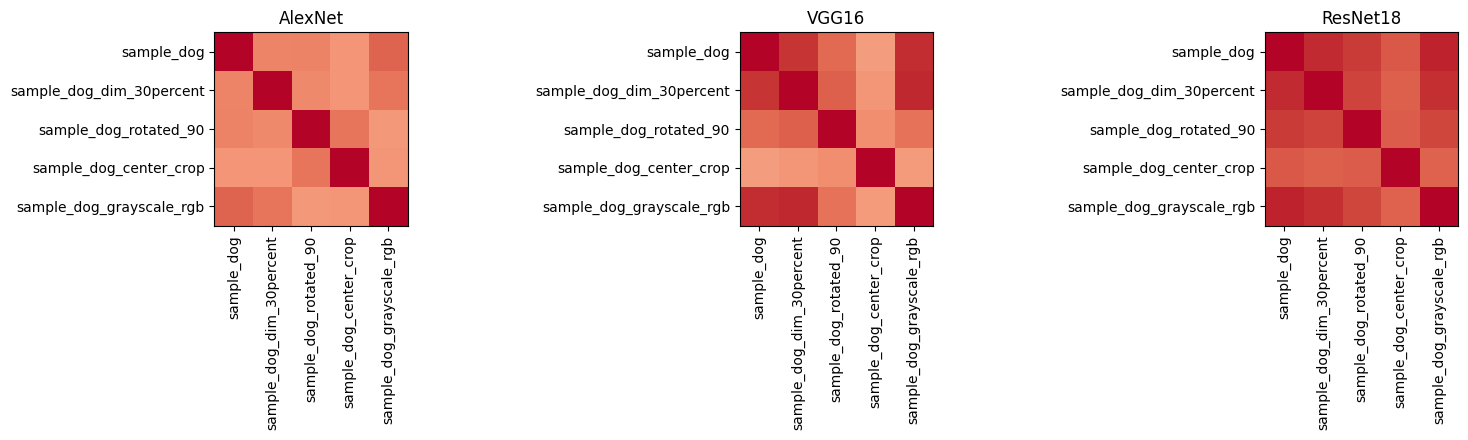

In [12]:
@torch.inference_mode()
def embed(model_name, pil_image):
    model = models[model_name]
    batch = weights_map[model_name].transforms()(pil_image.convert('RGB')).unsqueeze(0).to(DEVICE)
    captured = []
    layer = model.fc if model_name == 'ResNet18' else model.classifier[6]
    handle = layer.register_forward_pre_hook(lambda module, args: captured.append(args[0].detach().flatten(1)))
    try:
        _ = model(batch)
    finally:
        handle.remove()
    return captured[0].squeeze(0).cpu().numpy()

from sklearn.metrics.pairwise import cosine_similarity
# Always include the transformed copies; add independently photographed images for a more informative task.
representation_images = {**images, **{f'{example_name}_{k}': v for k, v in variants.items() if k != 'original'}}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, models):
    E = np.stack([embed(name, im) for im in representation_images.values()])
    sim = cosine_similarity(E)
    out = ax.imshow(sim, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_title(name)
    ax.set_xticks(range(len(representation_images)), labels=list(representation_images), rotation=90)
    ax.set_yticks(range(len(representation_images)), labels=list(representation_images))
plt.tight_layout(); plt.show()


## Visual E — What do intermediate convolutional features look like?

Use a temporary forward hook to capture **early** and **late** feature maps from the same image. Each displayed map is one selected feature channel normalized separately for visibility. Activations do not have an immediate human-readable semantic label, and their intensity scales cannot be compared directly across networks.

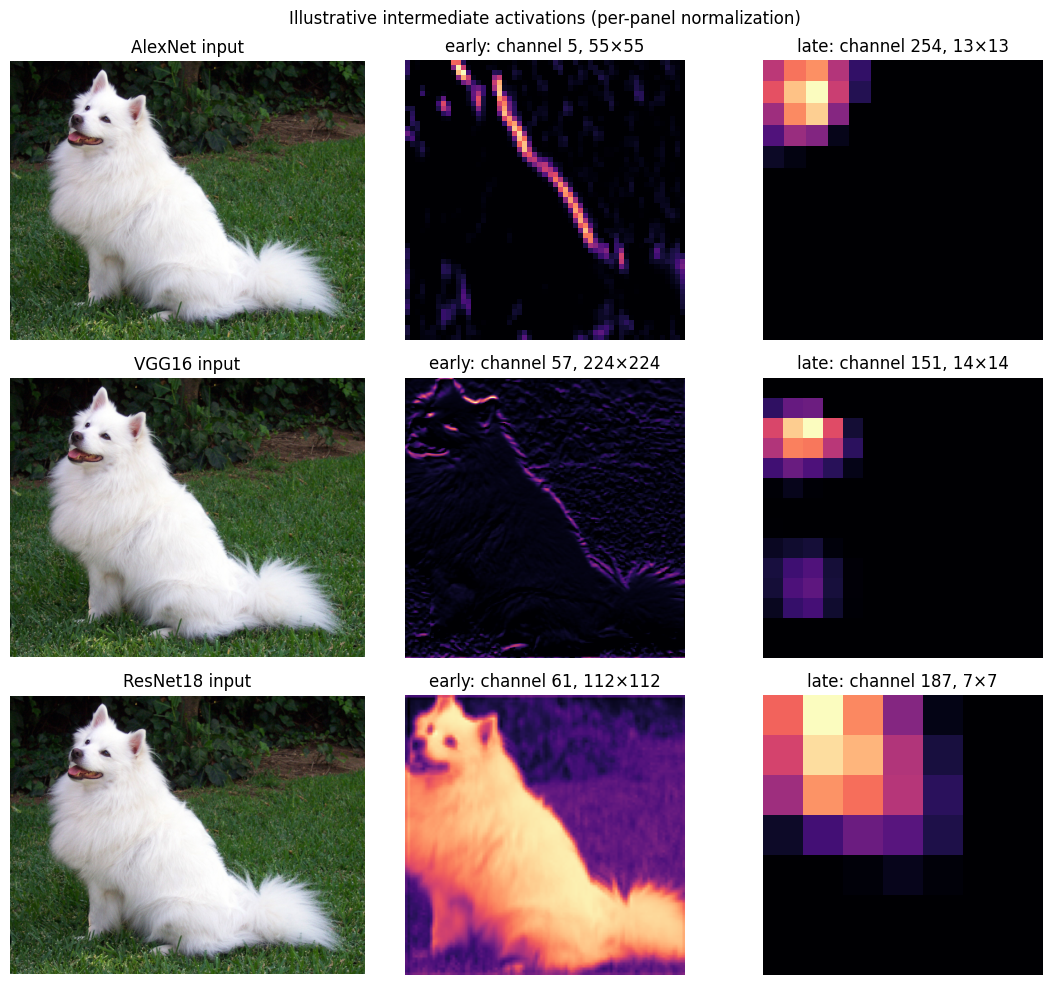

In [16]:
@torch.inference_mode()
def capture_feature_maps(model_name, image):
    net = models[model_name]
    net.eval()

    activations = {}
    hooks = []

    if model_name == 'AlexNet':
        layers = [
            ('early', net.features[0]),
            ('late', net.features[10])
        ]
    elif model_name == 'VGG16':
        layers = [
            ('early', net.features[0]),
            ('late', net.features[28])
        ]
    elif model_name == 'ResNet18':
        layers = [
            ('early', net.conv1),
            ('late', net.layer4[-1])
        ]
    else:
        raise ValueError(f"Unknown model: {model_name}")

    def make_hook(name):
        def hook(module, inputs, output):
            activations[name] = output.detach().cpu()
        return hook

    for name, layer in layers:
        hooks.append(
            layer.register_forward_hook(make_hook(name))
        )

    try:
        x = (
            weights_map[model_name]
            .transforms()(image.convert("RGB"))
            .unsqueeze(0)
            .to(DEVICE)
            )

        with torch.no_grad():
            net(x)
    finally:
        for hook in hooks:
            hook.remove()

    return activations

fig,axes=plt.subplots(3,3,figsize=(11,10))
for r,name in enumerate(models):
    activations=capture_feature_maps(name,example_image)
    axes[r,0].imshow(example_image);axes[r,0].set_title(f'{name} input')
    for c,key in enumerate(['early','late'],start=1):
        fmap=activations[key][0] # channels × height × width
        # Pick most variable channel for a non-flat example
        idx=int(fmap.flatten(1).var(dim=1).argmax())
        axes[r,c].imshow(fmap[idx].numpy(),cmap='magma')
        axes[r,c].set_title(f'{key}: channel {idx}, {fmap.shape[-2]}×{fmap.shape[-1]}')
    for ax in axes[r]:ax.axis('off')
plt.suptitle('Illustrative intermediate activations (per-panel normalization)')
plt.tight_layout();plt.show()

**Questions E1–E3.** How does spatial resolution change between early and late layers? Can you infer a channel's function from one image? How might early texture and edge responses transfer differently from later representations to plant images?

**Question 8.** Which image transformations preserve feature similarity in each network? Why is a feature embedding more general-purpose than a 1,000-class prediction vector?

**Question 9.** How would you test whether these embeddings distinguish two crop species, two cultivars, or healthy and stressed leaves? Specify an independent labeled evaluation design.

## Part 6 — Transfer learning: design an experiment (no retraining required)
Imagine you have a labeled image dataset with two categories: **healthy leaf** and **visibly stressed leaf**.

Compare two approaches:
1. **Frozen feature extractor:** Use pretrained embeddings and fit a simple supervised classifier on the labeled training set.
2. **Fine-tuning:** Replace the final 1,000-class output with a two-class head and train the head (optionally unfreezing deeper layers).

**Question 10.** What data split would you use? Explain how you would avoid leakage when multiple images come from the same plant, plot or field.

**Question 11.** In what circumstances might pretraining on ImageNet be insufficient for disease or stress classification? Propose a more relevant source of pretraining data.

**Question 12.** Explain why evaluating the model only on the same plants or plots used for fitting may overstate generalizability.

## Visual F — Utility map: choose a network for a scientific task

The table below is a **discussion scaffold**, not a benchmark verdict. Students must defend their model choice using the experimental plots above and the requirements of the deployment scenario.

| Task | What matters | Architectural considerations |
|---|---|---|
| Classroom exploration of early CNNs | Historical design, ease of interpretation | AlexNet is a useful reference point |
| Offline feature extraction | Embedding quality, memory and runtime | Compare VGG16 and ResNet18 on the actual dataset |
| Edge / mobile phenotyping | Latency, size, power, robustness | ResNet18 is a plausible starting point of these three; still benchmark on target hardware |
| Fine-tuning on crop disease images | Label quality, domain shift, generalization | Test frozen features against partially/fully fine-tuned heads |
| Object localization in field imagery | Spatial outputs and localization metrics | These classifiers alone are not object detectors; use appropriate detection/segmentation architectures |

**Extension F1.** Given 100 labeled leaf images, design an experiment comparing frozen features + logistic regression with fine-tuning. Specify train/test splits, the relevant biological unit for splitting, class imbalance, and metrics beyond accuracy.

**Extension F2.** Explain why the term *pretrained model* is more precise here than calling all three modern *foundation models*. These are supervised ImageNet pretrained CNN classifiers, whereas foundation models usually refer to models pretrained at broader scale that can be adapted across many tasks.

## Submission checklist
- [ ] Parameters and computational cost table
- [ ] Predictions on at least three images (ideally one crop/plant photograph)
- [ ] Perturbation results and interpretation
- [ ] Feature similarity figure
- [ ] Short answers to Questions 1–12
- [ ] A 150–200 word conclusion: **Which model would you choose for agricultural image analysis, and what additional evidence would you need?**

## Instructor notes
- Default task uses frozen models. **No training is performed.**
- Do not call the top-1 softmax score 'accuracy' or interpret it as a calibrated confidence of correctness.
- Only a labeled dataset supports a measured classification accuracy; a few selected photographs support exploration, not validation.
- Model weights require internet access once; VGG16 downloads ~528 MB. Colab CPU is viable but may be slow.
- Advanced follow-on lab: attach and train a new classification head on a labeled agricultural dataset, keeping training and test images separated by plant/plot/field.

## References
- PyTorch TorchVision models and weights: https://docs.pytorch.org/vision/main/models.html
- AlexNet: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.alexnet.html
- VGG16: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.vgg16.html
- ResNet18: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html
